# 00 - Data preparation (run this first)

**Why the first version failed.** Your images are not text lines. They are ~3000x4000 phone photos of a *whole
handwritten paragraph* (5-9 lines, margins, shadows, sometimes a cloth background). The old notebook shrank the whole
photo to 64 px height, so each page became a ~50 px wide smudge and then got stretched 20-30x so CTC had enough time
steps. No model can learn from that.

**What this notebook does**

1. finds the labelled pages (`Hindi-Val`, `Marathi-Val`; the `*-Test` folders have no text labels)
2. splits them **by writer** (file prefix before `_`), so the same hand is never in train and test
3. cleans every photo (lighting, paper detection, deskew), cuts it into text lines, resizes each line to the same height
4. stitches the lines of a page into one long strip - that strip is what the models read, and the label is the paragraph text
5. builds the character vocabulary from the **training** text only
6. checks that CTC is feasible for every page and flags suspicious pages

Outputs go to `htr_outputs/` (manifest, cached lines, vocabulary, config).

In [1]:
# Run once if packages are missing (remove the leading # ):
# %pip install torch opencv-python numpy pandas matplotlib scikit-learn

In [2]:
import sys, random, pickle
from pathlib import Path
sys.path.insert(0, ".")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
import htr_data as D

DATA_ROOT = Path(r"C:\Users\dasar\Desktop\DataSet\Sentence Level")     # <-- change if your path is different
OUT_DIR   = Path("htr_outputs")

cfg = dict(D.DEFAULT_CFG, data_root=str(DATA_ROOT), out_dir=str(OUT_DIR))
print(cfg)
assert DATA_ROOT.exists(), "DATA_ROOT not found - fix the path in this cell"

{'H': 48, 'cache_h': 64, 'target_width': 2000, 'heading_mode': 'auto', 'seed': 42, 'batch_size': 4, 'num_workers': 0, 'data_root': 'C:\\Users\\dasar\\Desktop\\DataSet\\Sentence Level', 'out_dir': 'htr_outputs'}


## 1. What is in the dataset folder?

In [3]:
folders = D.find_language_folders(DATA_ROOT)
for lang, info in folders.items():
    print(lang)
    for p in info["labelled"]:
        print("   labelled  :", p.name, "-", len(list(p.glob("*.txt"))), "pages with .txt label")
    for p in info["unlabelled"]:
        n = len([q for q in p.glob("*") if q.suffix.lower() in D.IMG_EXT])
        print("   unlabelled:", p.name, "-", n, "images, no .txt (used only for the final language-ID demo)")

Hindi
   labelled  : Hindi-Val - 300 pages with .txt label
   unlabelled: Hindi-Test - 700 images, no .txt (used only for the final language-ID demo)
Marathi
   labelled  : Marathi-Val - 300 pages with .txt label
   unlabelled: Marathi-Test - 700 images, no .txt (used only for the final language-ID demo)


In [4]:
man0 = D.build_manifest(DATA_ROOT)
print(man0.groupby("language").agg(pages=("id", "count"), writers=("writer", "nunique")))
print("\nlabel length in characters:")
print(man0.text.str.len().describe().round(1))
for lang in ["Hindi", "Marathi"]:
    r = man0[man0.language == lang].iloc[0]
    print("\n", lang, r.id, "\n", r.text)

          pages  writers
language                
Hindi       300       36
Marathi     300       23

label length in characters:
count    600.0
mean     254.5
std       60.3
min      125.0
25%      210.0
50%      249.0
75%      298.0
max      442.0
Name: text, dtype: float64

 Hindi hi_101_5708 
 बैटल रोयाल जापानी लेखक कौशुन ताकामी का उपन्यास है। वर्ष १९०० में ४४ देशों में लगभग १,००,००० चीते थे। हम कैसे उसे अधिक सुरक्षित महसूस करते हैं? डॉक्टर के बुलाने तक इंतज़ार के दौरान सॉंस लेते रहने की

 Marathi ma_136_113071 
 यामुळे सिॲटल हे महत्वाचे प्रवासाचे ठिकाण म्हणून ओळखू जाऊ लागले. रथिका १९९९ पासून आपल्या लग्नानंतर ती नवी दिल्लीमध्ये राहत आहे. तुमचे उदाहरण पाहून त्या विद्यार्थ्याला प्रेरणा झाली पाहिजे. व नंतर ती हरवली असावीत का? यामध्ये प्राचीन कालखंडातील सिंधू संस्कृतीतील काही पुरावशेषांचा समावेश आहे.


## 2. Check the preprocessing visually (do not skip)

Left: the cleaned page with one **green box per detected text line**. Right: the strip that the model will read.

You want: one green box per handwritten line, no boxes on the cloth/background, strips that look like a single readable row.
If a heading is wrongly kept or dropped, set `cfg["heading_mode"]` to `"drop"` or `"keep"` in the config cell and re-run.

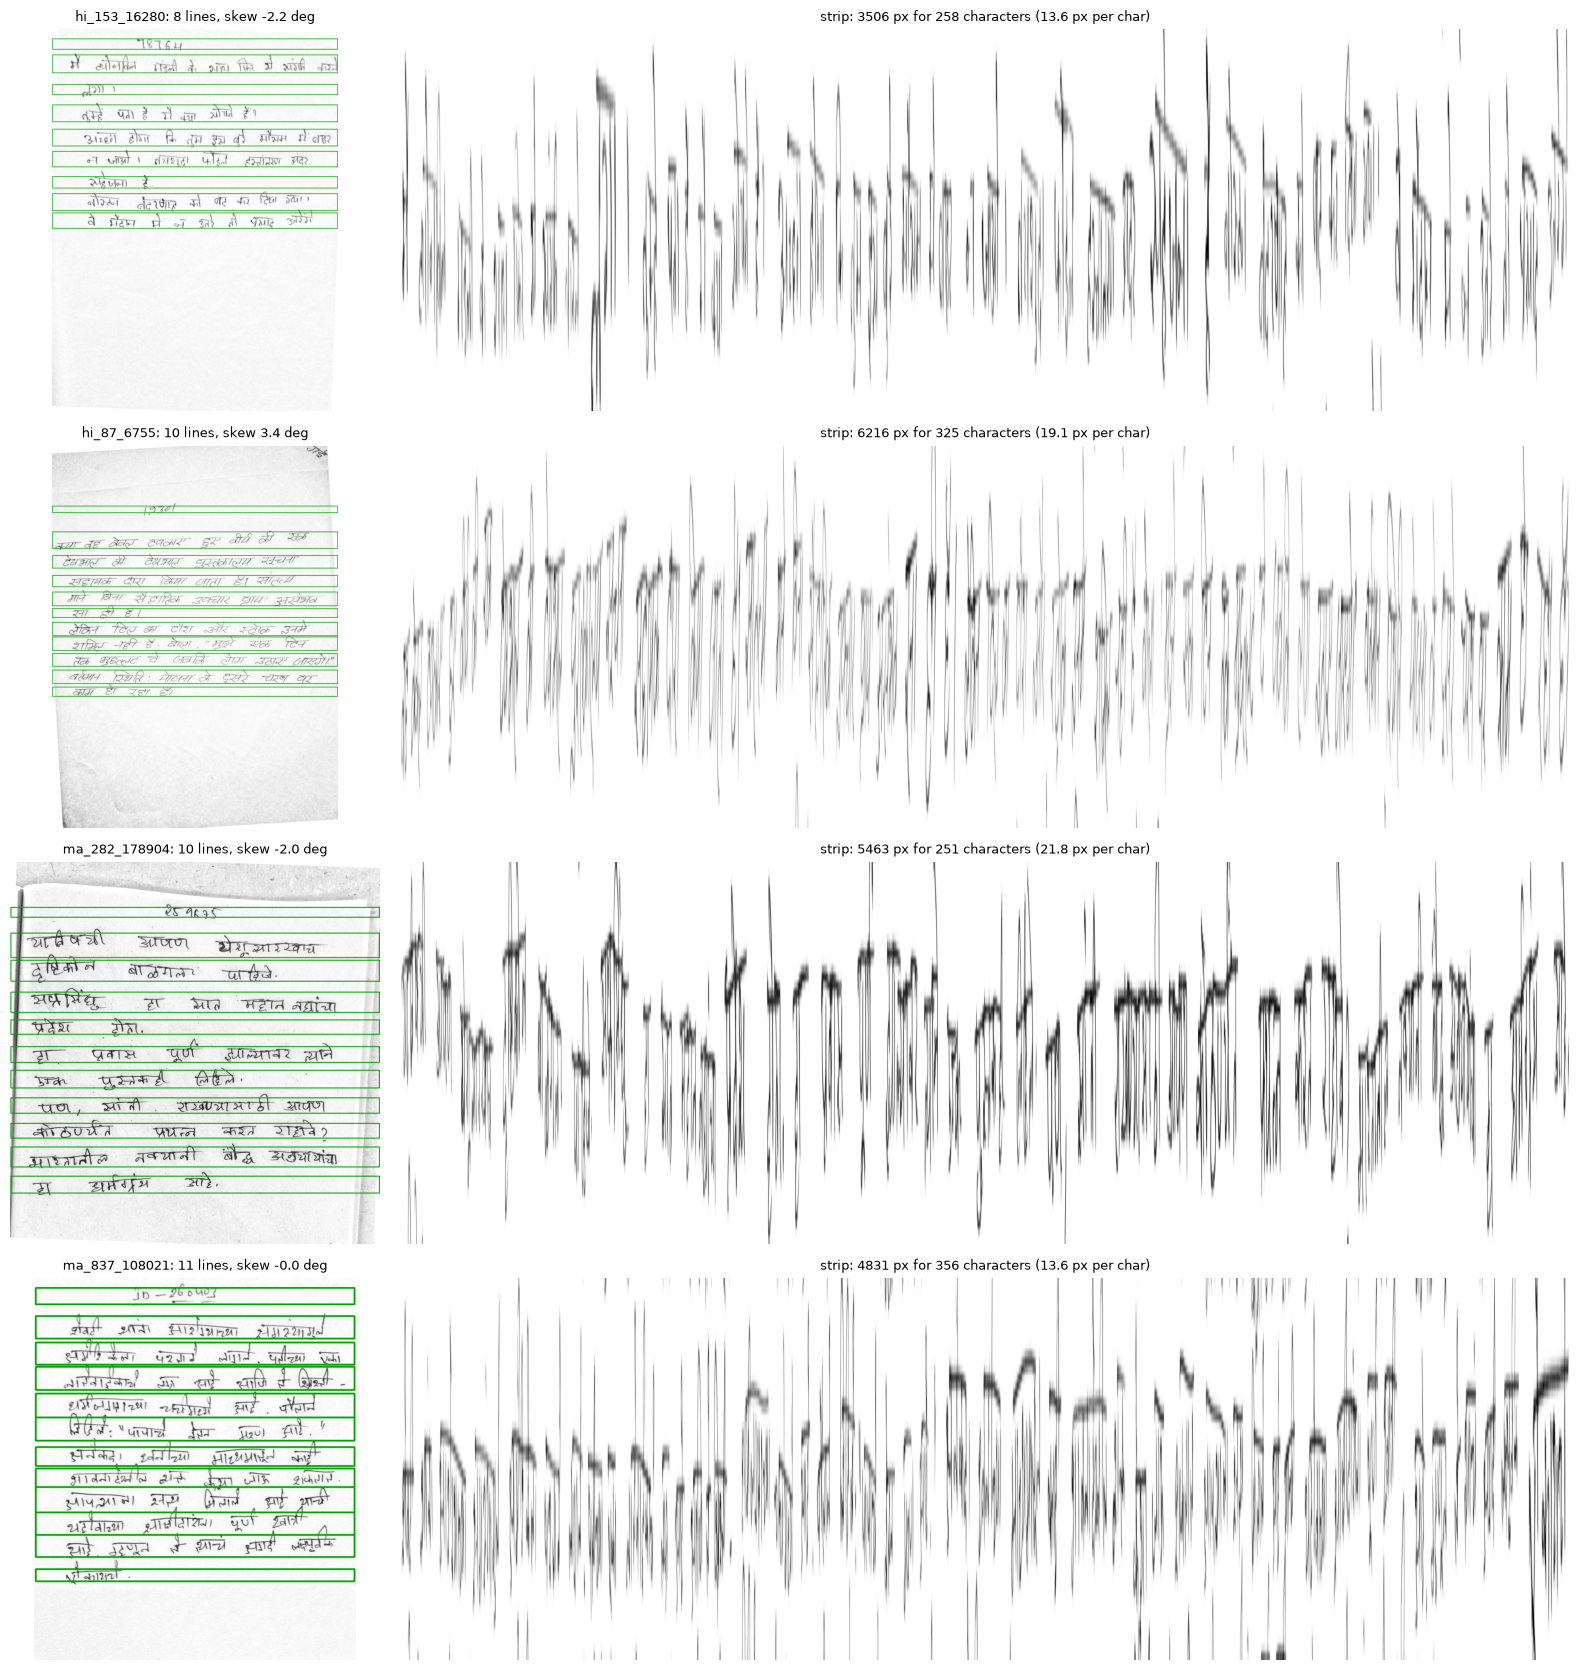

In [5]:
pick = pd.concat([man0[man0.language == l].sample(2, random_state=3) for l in ["Hindi", "Marathi"]])
fig, axes = plt.subplots(len(pick), 2, figsize=(16, 4.2 * len(pick)), gridspec_kw={"width_ratios": [1, 3]})
for ax_row, (_, r) in zip(axes, pick.iterrows()):
    vis, lines, info = D.qc_image(r.image, cfg)
    ax_row[0].imshow(vis); ax_row[0].axis("off")
    ax_row[0].set_title(f"{r.id}: {info['n_lines']} lines, skew {info['angle']:.1f} deg", fontsize=9)
    strip = D.stitch_lines(lines, cfg["H"], 30)
    ax_row[1].imshow(strip, cmap="gray", aspect="auto"); ax_row[1].axis("off")
    ax_row[1].set_title(f"strip: {strip.shape[1]} px for {len(r.text)} characters ({strip.shape[1]/len(r.text):.1f} px per char)", fontsize=9)
plt.tight_layout(); plt.show()

## 3. Preprocess every labelled page, split by writer, build vocabulary

This takes a few minutes (about one second per page).

In [6]:
man, char2idx = D.prepare_dataset(cfg, workers=4)
print("pages kept:", len(man), "| vocabulary:", len(char2idx), "characters (+1 CTC blank)")

split: Hindi: 36 writers -> pages {'train': 207, 'val': 44, 'test': 49}
split: Marathi: 23 writers -> pages {'train': 216, 'val': 43, 'test': 41}
  preprocessed 50/600 pages
  preprocessed 100/600 pages
  preprocessed 150/600 pages
  preprocessed 200/600 pages
  preprocessed 250/600 pages
  preprocessed 300/600 pages
  preprocessed 350/600 pages
  preprocessed 400/600 pages
  preprocessed 450/600 pages
  preprocessed 500/600 pages
  preprocessed 550/600 pages
  preprocessed 600/600 pages
             id                  err
233  hi_88_8428  no text lines found
236  hi_88_9067  no text lines found
pages kept: 598 | vocabulary: 155 characters (+1 CTC blank)


split     test  train  val
language                  
Hindi       49    205   44
Marathi     41    216   43
writers that appear in more than one split: 0
       n_lines  strip_w  required       T
count    598.0    598.0     598.0   598.0
mean       8.6   4402.9     255.2  1100.4
std        3.0   1909.4      60.3   477.3
min        1.0     17.0     126.0     4.0
25%        7.0   3294.5     211.0   823.5
50%        9.0   4214.0     250.0  1053.0
75%       11.0   5370.5     298.0  1342.0
max       17.0  17260.0     442.0  4315.0
heading dropped on 359 pages | footer/watermark dropped on 23
CTC-feasible: 573 / 598  | usable for training: 518 / 598


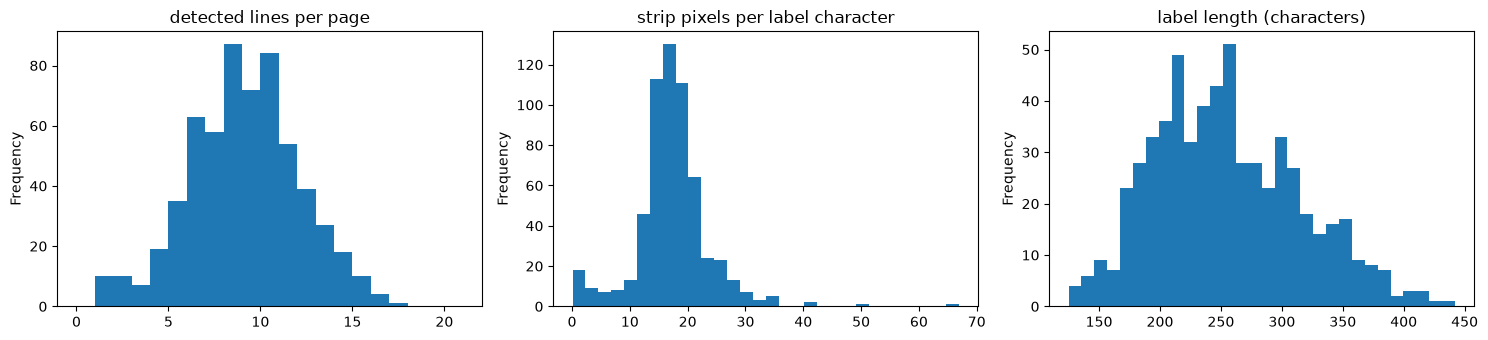

In [7]:
print(man.groupby(["language", "split"]).size().unstack())
print("writers that appear in more than one split:", int(man.groupby("writer").split.nunique().gt(1).sum()))
print(man[["n_lines", "strip_w", "required", "T"]].describe().round(1))
print("heading dropped on", int(man.dropped_heading.sum()), "pages | footer/watermark dropped on", int(man.dropped_footer.sum()))
print("CTC-feasible:", int(man.feasible.sum()), "/", len(man), " | usable for training:", int(man.train_ok.sum()), "/", len(man))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
man.n_lines.plot.hist(ax=ax[0], bins=range(0, 22)); ax[0].set_title("detected lines per page")
man.ratio.plot.hist(ax=ax[1], bins=30);           ax[1].set_title("strip pixels per label character")
man.text.str.len().plot.hist(ax=ax[2], bins=30);  ax[2].set_title("label length (characters)")
plt.tight_layout(); plt.show()

**Reading the plots.** "Pixels per character" should be a fairly narrow peak. Pages far from the peak usually have a
segmentation problem (merged lines, missed lines, a heading that is or is not in the label). Such *training* pages are
excluded automatically (`train_ok = False`); validation and test pages are never dropped.

In [8]:
bad = man[~man.train_ok][["id", "split", "n_lines", "strip_w", "required", "T", "ratio"]]
print(len(bad), "pages excluded from training")
print(bad.round(1).head(25).to_string(index=False))
if len(bad) > 0.25 * (man.split == "train").sum():
    print("\nMORE THAN 25% excluded - look at the QC pictures above again and adjust heading_mode / the page photos.")

80 pages excluded from training
          id split  n_lines  strip_w  required      T  ratio
 hi_101_7649 train      3.0    750.0       232  187.0    3.2
 hi_101_8877 train      8.0   6559.0       158 1639.0   41.5
hi_126_10063   val      2.0    295.0       200   73.0    1.5
hi_126_13311   val      5.0   1873.0       226  468.0    8.3
 hi_126_9709   val      2.0    550.0       126  137.0    4.4
 hi_126_9807   val      2.0    296.0       194   74.0    1.5
hi_138_42899  test      6.0   2382.0       234  595.0   10.2
hi_142_14968 train     14.0   8514.0       284 2128.0   30.0
hi_142_17249 train     10.0   5610.0       203 1402.0   27.8
hi_142_17420 train     14.0   7890.0       281 1972.0   28.1
hi_142_19402 train     11.0   6185.0       207 1546.0   30.0
hi_142_21692 train     12.0   6707.0       220 1676.0   30.5
hi_142_21841 train     12.0   6679.0       234 1669.0   28.5
hi_142_21844 train     11.0   7347.0       258 1836.0   28.6
hi_145_43177 train      2.0    312.0       177   78.0

C:\Users\dasar\AppData\Local\Temp\ipykernel_16456\4049014473.py:8: UserWarning: Glyph 2351 (\N{DEVANAGARI LETTER YA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\dasar\AppData\Local\Temp\ipykernel_16456\4049014473.py:8: UserWarning: Glyph 2313 (\N{DEVANAGARI LETTER U}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\dasar\AppData\Local\Temp\ipykernel_16456\4049014473.py:8: UserWarning: Glyph 2354 (\N{DEVANAGARI LETTER LA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\dasar\AppData\Local\Temp\ipykernel_16456\4049014473.py:8: UserWarning: Glyph 2335 (\N{DEVANAGARI LETTER TTA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\dasar\AppData\Local\Temp\ipykernel_16456\4049014473.py:8: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\dasar\AppData\Local\Temp\ipykernel_16456\4049014473.py:8: UserWar

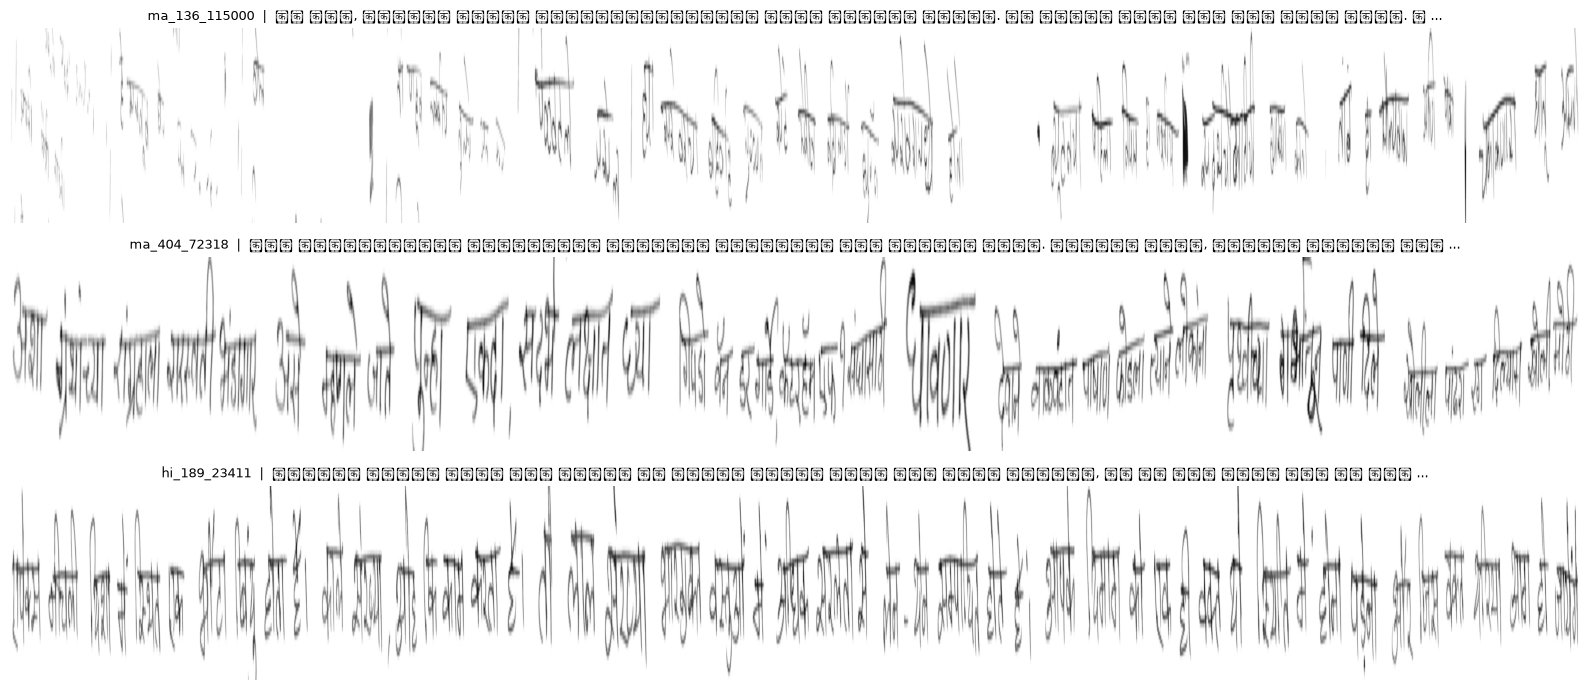

In [9]:
# a few ready-to-train strips with their labels
tr = man[(man.split == "train") & man.train_ok].sample(3, random_state=0)
fig, axes = plt.subplots(3, 1, figsize=(16, 7))
for ax, (_, r) in zip(axes, tr.iterrows()):
    lines = pickle.load(open(r.cache, "rb"))
    ax.imshow(D.stitch_lines(lines, cfg["H"], 30), cmap="gray", aspect="auto"); ax.axis("off")
    ax.set_title(r.id + "  |  " + r.text[:90] + " ...", fontsize=9)
plt.tight_layout(); plt.show()

In [10]:
# do validation/test pages share long phrases with the training text? (matters for the language-model experiment)
def shingles(t, k=6):
    w = t.split()
    return {" ".join(w[i:i + k]) for i in range(len(w) - k + 1)}

tr_sh = set().union(*[shingles(t) for t in man[man.split == "train"].text])
for s in ("val", "test"):
    texts = man[man.split == s].text
    hit = sum(bool(shingles(t) & tr_sh) for t in texts)
    print(f"{s}: {hit}/{len(texts)} pages share a 6-word phrase with the training text")
print("\nfiles written to", OUT_DIR.resolve())
print("next: notebook 01")

val: 3/87 pages share a 6-word phrase with the training text
test: 2/90 pages share a 6-word phrase with the training text

files written to C:\Users\dasar\Downloads\Final Year Capstone Project\htr_outputs
next: notebook 01
